# Lista 5 — Questão 07: Regras de associação com Apriori (base Titanic)

**Disciplina:** Inteligência Artificial — Profa. Cristiane Neri Nobre
**Aluno:** ____________________

Objetivo: gerar regras de associação que descrevam o perfil dos passageiros do Titanic e sua relação com a sobrevivência, usando itens de **presença** (`Classe=1ª`) e de **ausência** (`NÃO Classe=1ª`).

Roteiro do notebook (segue a numeração do enunciado):

1. Pré-processamento — valores ausentes, remoção de atributos, discretização e codificação one-hot
2. Itens de ausência (`NÃO atributo=valor`)
3. Geração das regras — Apriori, ajuste de suporte/confiança, métricas (suporte, confiança, lift)
4. Análise dos resultados — regras mais relevantes e regras com consequente de sobrevivência

In [1]:
# Bibliotecas. No Google Colab o mlxtend já vem instalado; se faltar, descomente a linha abaixo.
# !pip install mlxtend

import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

# Paleta usada nos gráficos (tons de azul para magnitude; laranja/azul/cinza para categorias)
AZUL, LARANJA, CINZA, TINTA = "#2a78d6", "#eb6834", "#9a9893", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA,
                     "xtick.color": TINTA, "ytick.color": TINTA, "font.size": 10})

## 0. Carregamento da base

Base **Titanic** do Kaggle (`train.csv`, 891 passageiros, 12 colunas). O arquivo é lido de um espelho público no GitHub; se você tiver o CSV localmente (por exemplo, o arquivo disponibilizado no SGA), basta trocar o caminho em `CAMINHO_LOCAL`.

In [2]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
CAMINHO_LOCAL = "titanic.csv"

try:
    df_original = pd.read_csv(CAMINHO_LOCAL)
except FileNotFoundError:
    df_original = pd.read_csv(URL)

df = df_original.copy()
print("Dimensão:", df.shape)
df.head()

Dimensão: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Quantidade e percentual de valores ausentes por coluna
ausentes = pd.DataFrame({"ausentes": df.isna().sum(),
                         "%": (df.isna().mean() * 100).round(1)})
ausentes[ausentes.ausentes > 0]

,ausentes,%
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


## 1. Pré-processamento

### 1(a) Valores ausentes e remoção de atributos

| Coluna | Ausentes | Tratamento |
|---|---|---|
| `Age` | 177 (19,9%) | imputação pela **mediana da idade do grupo (título do nome × classe)** |
| `Embarked` | 2 (0,2%) | imputação pela **moda** (`S` = Southampton) |
| `Cabin` | 687 (77,1%) | **removida** — informação ausente para a maioria dos passageiros |

Por que usar o título do nome na imputação da idade? O título (`Mr`, `Mrs`, `Miss`, `Master`) carrega informação de idade: `Master` designava meninos, `Miss` mulheres solteiras (em geral mais jovens). Imputar pela mediana global (28 anos) jogaria os 177 passageiros na mesma faixa etária e criaria regras artificiais; a mediana por título × classe preserva a distribuição etária de cada grupo. Depois de usado, o nome é descartado.

Atributos removidos por não serem úteis para regras de associação:
- `PassengerId`, `Name`, `Ticket` — identificadores (valores praticamente únicos, nunca atingiriam suporte mínimo);
- `Cabin` — 77% ausente;
- `SibSp` e `Parch` — substituídos por um único atributo `Família` (tamanho do grupo familiar = SibSp + Parch + 1).

In [4]:
# Extrai o título do nome: "Braund, Mr. Owen Harris" -> "Mr"
df["Titulo"] = df["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
# Agrupa variações do mesmo título e junta os títulos raros (Dr, Rev, Col, ...) em "Raro"
df["Titulo"] = df["Titulo"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
                                     "Lady": "Mrs", "the Countess": "Mrs"})
df.loc[~df["Titulo"].isin(["Mr", "Mrs", "Miss", "Master"]), "Titulo"] = "Raro"

# Mediana da idade por (título, classe) — usada para imputar
print(df.groupby(["Titulo", "Pclass"])["Age"].median().unstack().round(1))

mediana_grupo = df.groupby(["Titulo", "Pclass"])["Age"].transform("median")
mediana_titulo = df.groupby("Titulo")["Age"].transform("median")   # reserva, se o grupo não tiver mediana
df["Age"] = df["Age"].fillna(mediana_grupo).fillna(mediana_titulo)

# Embarque: moda
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Tamanho da família = irmãos/cônjuge + pais/filhos + o próprio passageiro
df["TamFamilia"] = df["SibSp"] + df["Parch"] + 1

# Remove identificadores e colunas não úteis
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "SibSp", "Parch", "Titulo"])
print("\nAusentes após o tratamento:", int(df.isna().sum().sum()))
df.head()

Pclass     1     2     3
Titulo                  
Master   4.0   1.0   4.0
Miss    30.0  24.0  18.0
Mr      40.0  31.0  26.0
Mrs     40.0  32.0  31.0
Raro    49.0  46.5   NaN

Ausentes após o tratamento: 0


,Survived,Pclass,Sex,Age,Fare,Embarked,TamFamilia
0,0,3,male,22.0,7.2500,S,2
1,1,1,female,38.0,71.2833,C,2
2,1,3,female,26.0,7.9250,S,1
3,1,1,female,35.0,53.1000,S,2
4,0,3,male,35.0,8.0500,S,1


### 1(b) Discretização dos atributos numéricos

O Apriori trabalha com itens categóricos, então `Age`, `Fare` e `TamFamilia` foram discretizados em faixas. Critérios usados:

- **Idade** — `0-17`, `18-22`, `23-40`, `41+`.
  - `0-17`: menores de idade — é o grupo protegido pelo protocolo "mulheres e crianças primeiro".
  - `18-22`: adultos jovens, majoritariamente solteiros e viajando na 3ª classe.
  - `23-40`: concentra o núcleo da distribuição (mediana ≈ 28 anos).
  - `41+`: adultos mais velhos; acima de 60 anos há só 22 passageiros, então não vale abrir outra faixa (ela nunca atingiria o suporte mínimo).
  - Faixas mais finas (ex.: 0–5, 6–12) teriam suporte < 5% e não gerariam regras.
- **Tarifa** (`Fare`, em libras) — `Baixa` (≤ 10), `Média` (10–30), `Alta` (> 30). Os cortes 10 e 30 são arredondamentos dos tercis (8,6 e 26,0) e dos quartis (7,9 / 14,5 / 31,0), gerando três faixas de tamanho parecido e de leitura fácil.
- **Família** — `Sozinho` (1), `Pequena` (2–4), `Grande` (5+). Separa quem viajava só, famílias pequenas e famílias numerosas, que têm comportamentos de sobrevivência bem diferentes (ver tabela abaixo).
- `Pclass`, `Sex`, `Embarked` e `Survived` já são categóricos; só foram renomeados para facilitar a leitura das regras.

In [5]:
dados = pd.DataFrame({
    "Classe":     df["Pclass"].map({1: "1ª", 2: "2ª", 3: "3ª"}),
    "Sexo":       df["Sex"].map({"male": "Masculino", "female": "Feminino"}),
    "Idade":      pd.cut(df["Age"], bins=[-1, 17, 22, 40, 200],
                         labels=["0-17", "18-22", "23-40", "41+"]).astype(str),
    "Família":    pd.cut(df["TamFamilia"], bins=[0, 1, 4, 100],
                         labels=["Sozinho", "Pequena", "Grande"]).astype(str),
    "Tarifa":     pd.cut(df["Fare"], bins=[-1, 10, 30, 1e9],
                         labels=["Baixa", "Média", "Alta"]).astype(str),
    "Embarque":   df["Embarked"].map({"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"}),
    "Sobreviveu": df["Survived"].map({1: "Sim", 0: "Não"}),
})
dados.head()

,Classe,Sexo,Idade,Família,Tarifa,Embarque,Sobreviveu
0,3ª,Masculino,18-22,Pequena,Baixa,Southampton,Não
1,1ª,Feminino,23-40,Pequena,Alta,Cherbourg,Sim
2,3ª,Feminino,23-40,Sozinho,Baixa,Southampton,Sim
3,1ª,Feminino,23-40,Pequena,Alta,Southampton,Sim
4,3ª,Masculino,23-40,Sozinho,Baixa,Southampton,Não


In [6]:
# Distribuição de cada faixa (suporte do item) e taxa de sobrevivência dentro dela
ordem_valores = {"Classe": ["1ª", "2ª", "3ª"], "Sexo": ["Feminino", "Masculino"],
                 "Idade": ["0-17", "18-22", "23-40", "41+"], "Família": ["Sozinho", "Pequena", "Grande"],
                 "Tarifa": ["Baixa", "Média", "Alta"], "Embarque": ["Southampton", "Cherbourg", "Queenstown"]}
linhas = []
for atr, valores in ordem_valores.items():
    for valor in valores:
        grupo = dados[dados[atr] == valor]
        linhas.append({"Atributo": atr, "Valor": valor, "Passageiros": len(grupo),
                       "Suporte": round(len(grupo) / len(dados), 3),
                       "Taxa de sobrevivência": round((grupo["Sobreviveu"] == "Sim").mean(), 3)})
resumo_faixas = pd.DataFrame(linhas)
resumo_faixas.to_csv("resumo_faixas.csv", index=False)
taxa_geral = (dados["Sobreviveu"] == "Sim").mean()
print(f"Taxa geral de sobrevivência: {taxa_geral:.3f}")
resumo_faixas.reset_index(drop=True)

Taxa geral de sobrevivência: 0.384


,Atributo,Valor,Passageiros,Suporte,Taxa de sobrevivência
0,Classe,1ª,216,0.242,0.630
1,Classe,2ª,184,0.207,0.473
2,Classe,3ª,491,0.551,0.242
3,Sexo,Feminino,314,0.352,0.742
4,Sexo,Masculino,577,0.648,0.189
5,Idade,0-17,117,0.131,0.538
6,Idade,18-22,151,0.169,0.371
7,Idade,23-40,472,0.530,0.356
8,Idade,41+,151,0.169,0.364
9,Família,Sozinho,537,0.603,0.304


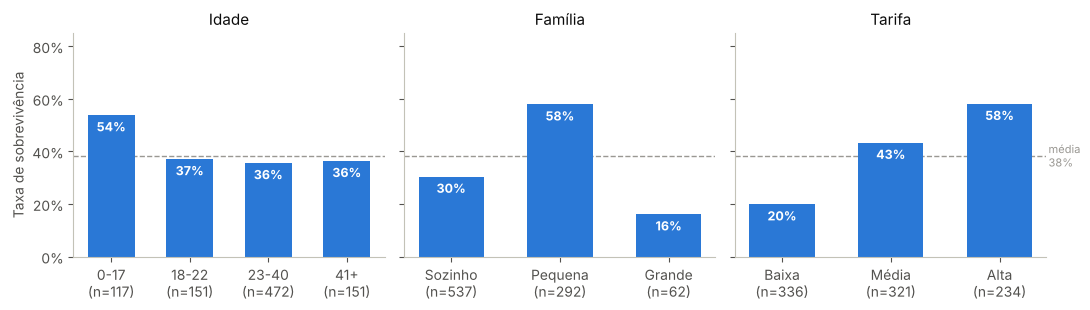

In [7]:
# Gráfico: taxa de sobrevivência por faixa dos atributos discretizados
import os
os.makedirs("figs", exist_ok=True)

fig, eixos = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True)
for ax, atr in zip(eixos, ["Idade", "Família", "Tarifa"]):
    t = resumo_faixas[resumo_faixas.Atributo == atr]
    rotulos = [f"{v}\n(n={n})" for v, n in zip(t["Valor"], t["Passageiros"])]
    barras = ax.bar(rotulos, t["Taxa de sobrevivência"], color=AZUL, width=0.6)
    ax.axhline(taxa_geral, color=CINZA, lw=1, ls="--", zorder=0)
    for b, taxa in zip(barras, t["Taxa de sobrevivência"]):
        ax.text(b.get_x() + b.get_width() / 2, taxa - 0.015, f"{taxa:.0%}",
                ha="center", va="top", fontsize=9, color="white", fontweight="bold")
    ax.set_title(atr, fontsize=11, color="#0b0b0b")
    ax.set_ylim(0, 0.85)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
eixos[0].set_ylabel("Taxa de sobrevivência")
eixos[2].text(2.45, taxa_geral, f"média\n{taxa_geral:.0%}", va="center", fontsize=8, color=CINZA)
plt.tight_layout()
plt.savefig("figs/faixas_sobrevivencia.png", dpi=200, bbox_inches="tight")
plt.show()

### 1(c) Formato transacional / binário (one-hot)

Cada par `atributo=valor` vira uma coluna booleana (item). Cada passageiro é uma transação, e o item vale `True` quando o passageiro possui aquela característica — por exemplo `Classe=3ª`, `Idade=18-22`, `Sobreviveu=Não`.

In [8]:
itens_presenca = pd.get_dummies(dados, prefix_sep="=").astype(bool)
print("Itens de presença:", itens_presenca.shape[1])
print(list(itens_presenca.columns))
itens_presenca.head()

Itens de presença: 20
['Classe=1ª', 'Classe=2ª', 'Classe=3ª', 'Sexo=Feminino', 'Sexo=Masculino', 'Idade=0-17', 'Idade=18-22', 'Idade=23-40', 'Idade=41+', 'Família=Grande', 'Família=Pequena', 'Família=Sozinho', 'Tarifa=Alta', 'Tarifa=Baixa', 'Tarifa=Média', 'Embarque=Cherbourg', 'Embarque=Queenstown', 'Embarque=Southampton', 'Sobreviveu=Não', 'Sobreviveu=Sim']


,Classe=1ª,Classe=2ª,Classe=3ª,Sexo=Feminino,Sexo=Masculino,Idade=0-17,Idade=18-22,Idade=23-40,Idade=41+,Família=Grande,Família=Pequena,Família=Sozinho,Tarifa=Alta,Tarifa=Baixa,Tarifa=Média,Embarque=Cherbourg,Embarque=Queenstown,Embarque=Southampton,Sobreviveu=Não,Sobreviveu=Sim
0,False,False,True,False,True,False,True,False,False,False,True,False,False,True,False,False,False,True,True,False
1,True,False,False,True,False,False,False,True,False,False,True,False,True,False,False,True,False,False,False,True
2,False,False,True,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False,True
3,True,False,False,True,False,False,False,True,False,False,True,False,True,False,False,False,False,True,False,True
4,False,False,True,False,True,False,False,True,False,False,False,True,False,True,False,False,False,True,True,False


## 2. Itens de ausência (`NÃO atributo=valor`)

**Implementação.** Para cada item de presença `A=v` foi criada uma coluna `NÃO A=v` com a negação lógica da coluna original (`~coluna`): vale `True` para todo passageiro que **não** tem aquele valor. Assim, `NÃO Classe=1ª` reúne quem viajava na 2ª **ou** na 3ª classe, e o Apriori passa a tratá-lo como um item comum.

Dois cuidados foram necessários:

1. **Atributos binários não recebem itens de ausência.** Em `Sexo` e `Sobreviveu`, `NÃO Sexo=Feminino` é exatamente `Sexo=Masculino`. Criar o item de ausência só duplicaria todas as regras com outro nome. Por isso, os itens de ausência foram gerados apenas para atributos com 3 ou mais valores: `Classe`, `Idade`, `Família`, `Tarifa` e `Embarque` (16 itens).
2. **Remoção de combinações tautológicas.** Um itemset que contém dois itens do mesmo atributo é redundante ou impossível: `{Classe=1ª, NÃO Classe=3ª}` é igual a `{Classe=1ª}`, e a regra `{Classe=1ª} → {NÃO Classe=3ª}` tem confiança 100% por definição, sem dizer nada sobre os dados. Por isso, depois do Apriori, são descartados os itemsets frequentes em que o mesmo atributo aparece mais de uma vez. Como todo subconjunto de um itemset válido também é válido, o descarte não atrapalha o cálculo das regras.

In [9]:
# Atributos com 3+ valores recebem itens de ausência
atributos_multivalor = [a for a in dados.columns if dados[a].nunique() > 2]
print("Atributos com itens de ausência:", atributos_multivalor)

itens_ausencia = pd.DataFrame(index=itens_presenca.index)
for coluna in itens_presenca.columns:
    atributo = coluna.split("=")[0]
    if atributo in atributos_multivalor:
        itens_ausencia["NÃO " + coluna] = ~itens_presenca[coluna]   # negação lógica

transacoes = pd.concat([itens_presenca, itens_ausencia], axis=1)
print("Itens de ausência:", itens_ausencia.shape[1])
print("Total de itens:", transacoes.shape[1], "| Transações:", transacoes.shape[0])

# Suporte de cada item (fração de passageiros que possuem o item)
transacoes.mean().round(3).sort_values(ascending=False).to_frame("suporte").T

Atributos com itens de ausência: ['Classe', 'Idade', 'Família', 'Tarifa', 'Embarque']
Itens de ausência: 16
Total de itens: 36 | Transações: 891


,NÃO Família=Grande,NÃO Embarque=Queenstown,NÃO Idade=0-17,NÃO Idade=18-22,NÃO Idade=41+,NÃO Embarque=Cherbourg,NÃO Classe=2ª,NÃO Classe=1ª,NÃO Tarifa=Alta,Embarque=Southampton,...,NÃO Embarque=Southampton,Tarifa=Alta,Classe=1ª,Classe=2ª,Embarque=Cherbourg,Idade=41+,Idade=18-22,Idade=0-17,Embarque=Queenstown,Família=Grande
suporte,0.93,0.914,0.869,0.831,0.831,0.811,0.793,0.758,0.737,0.725,...,0.275,0.263,0.242,0.207,0.189,0.169,0.169,0.131,0.086,0.07


In [10]:
# Exemplo: o passageiro 0 (homem, 3ª classe, 22 anos) como transação
print([item for item, presente in transacoes.iloc[0].items() if presente])

['Classe=3ª', 'Sexo=Masculino', 'Idade=18-22', 'Família=Pequena', 'Tarifa=Baixa', 'Embarque=Southampton', 'Sobreviveu=Não', 'NÃO Classe=1ª', 'NÃO Classe=2ª', 'NÃO Idade=0-17', 'NÃO Idade=23-40', 'NÃO Idade=41+', 'NÃO Família=Grande', 'NÃO Família=Sozinho', 'NÃO Tarifa=Alta', 'NÃO Tarifa=Média', 'NÃO Embarque=Cherbourg', 'NÃO Embarque=Queenstown']


## 3. Geração das regras

### Funções auxiliares

- `atributo(item)`: devolve o atributo de um item (`"NÃO Classe=1ª"` → `"Classe"`).
- `sem_tautologia(itemset)`: `True` se cada atributo aparece no máximo uma vez no itemset.
- `gerar_regras(...)`: roda o Apriori, remove itemsets tautológicos e gera as regras com suporte, confiança e lift (com compatibilidade para versões antigas e novas do mlxtend).
- `filtrar_regras(...)`: aplica os filtros de qualidade descritos abaixo.

**Filtros de qualidade** (para evitar excesso de regras triviais):

1. **Consequente só com itens de presença.** Itens de ausência têm suporte muito alto (ex.: `NÃO Embarque=Queenstown` = 91%, `NÃO Família=Grande` = 93%), então qualquer antecedente "implica" esses itens com alta confiança e lift ≈ 1. Os itens de ausência continuam permitidos no **antecedente**, que é onde fazem sentido (como no exemplo do enunciado).
2. **Lift ≥ 1,2** — exige que o antecedente aumente em pelo menos 20% a chance do consequente em relação à base.
3. **Regras produtivas (melhoria ≥ 0,02).** Uma regra `A → C` só é mantida se sua confiança supera em pelo menos 2 pontos percentuais a confiança de **todas** as regras com antecedente menor (`A' ⊂ A`, incluindo o antecedente vazio, cuja confiança é o suporte de `C`). Isso elimina regras que apenas acrescentam itens irrelevantes a uma regra mais geral.

In [11]:
def atributo(item):
    # "NÃO Classe=1ª" -> "Classe" ; "Sexo=Feminino" -> "Sexo"
    return item.replace("NÃO ", "").split("=")[0]

def sem_tautologia(itemset):
    attrs = [atributo(i) for i in itemset]
    return len(attrs) == len(set(attrs))

def regras_mlxtend(frequentes, n_transacoes, conf_min):
    # O mlxtend >= 0.23.2 pede num_itemsets; versões antigas não aceitam esse argumento.
    try:
        return association_rules(frequentes, num_itemsets=n_transacoes,
                                 metric="confidence", min_threshold=conf_min)
    except TypeError:
        return association_rules(frequentes, metric="confidence", min_threshold=conf_min)

def gerar_regras(transacoes, sup_min, conf_min, max_len=4):
    # 1) Itemsets frequentes com o Apriori (max_len=4 -> antecedentes com até 3 itens)
    frequentes = apriori(transacoes, min_support=sup_min, use_colnames=True, max_len=max_len)
    n_bruto = len(frequentes)
    # 2) Remove itemsets com o mesmo atributo repetido (tautologias)
    frequentes = frequentes[frequentes["itemsets"].apply(sem_tautologia)].reset_index(drop=True)
    # 3) Regras de associação a partir dos itemsets frequentes
    regras = regras_mlxtend(frequentes, len(transacoes), conf_min)
    suportes = dict(zip(frequentes["itemsets"], frequentes["support"]))
    return regras, suportes, n_bruto, len(frequentes)

def eh_produtiva(regras, suportes, melhoria_min=0.02):
    # Compara a confiança de A -> C com a de todo A' ⊂ A (inclusive o vazio, conf = sup(C))
    manter = []
    for A, C, conf in zip(regras["antecedents"], regras["consequents"], regras["confidence"]):
        melhor = suportes[C]
        for k in range(1, len(A)):
            for sub in combinations(A, k):
                sub = frozenset(sub)
                melhor = max(melhor, suportes[sub | C] / suportes[sub])
        manter.append(conf - melhor >= melhoria_min)
    return np.array(manter, dtype=bool)

def filtrar_regras(regras, suportes, lift_min=1.2, melhoria_min=0.02):
    r = regras[regras["consequents"].apply(lambda s: not any(i.startswith("NÃO ") for i in s))]
    r = r[r["lift"] >= lift_min]
    if len(r):
        r = r[eh_produtiva(r, suportes, melhoria_min)]
    return r

def eh_sobrevivencia(consequente):
    return len(consequente) == 1 and atributo(next(iter(consequente))) == "Sobreviveu"

### 3(b) Ajuste do suporte mínimo e da confiança mínima

Foram testadas 6 configurações de suporte (3% a 20%) × 5 de confiança (50% a 90%). Para cada par, contamos:
- **regras brutas**: saída direta do Apriori + `association_rules`, sem nenhum filtro;
- **regras após filtros**: sem tautologias, consequente de presença, lift ≥ 1,2 e regras produtivas;
- quantas das regras filtradas têm consequente `Sobreviveu=Sim` e `Sobreviveu=Não`.

In [12]:
suportes_teste = [0.03, 0.05, 0.08, 0.10, 0.15, 0.20]
confiancas_teste = [0.5, 0.6, 0.7, 0.8, 0.9]

resultados = []
for s in suportes_teste:
    # Regras brutas (sem remover tautologias) para mostrar o efeito dos itens de ausência
    freq_bruto = apriori(transacoes, min_support=s, use_colnames=True, max_len=4)
    regras_brutas = regras_mlxtend(freq_bruto, len(transacoes), min(confiancas_teste))
    # Regras com o pipeline completo
    regras, sups, n_freq_bruto, n_freq = gerar_regras(transacoes, s, min(confiancas_teste))
    filtradas = filtrar_regras(regras, sups)
    for c in confiancas_teste:
        f = filtradas[filtradas["confidence"] >= c]
        sobrev = f[f["consequents"].apply(eh_sobrevivencia)]
        resultados.append({
            "suporte_min": s, "confianca_min": c,
            "itemsets_frequentes": n_freq_bruto,
            "regras_brutas": int((regras_brutas["confidence"] >= c).sum()),
            "regras_filtradas": len(f),
            "Sobreviveu=Sim": int(sobrev["consequents"].apply(lambda x: "Sobreviveu=Sim" in x).sum()),
            "Sobreviveu=Não": int(sobrev["consequents"].apply(lambda x: "Sobreviveu=Não" in x).sum()),
        })

grade = pd.DataFrame(resultados)
grade.to_csv("grade_parametros.csv", index=False)
grade

,suporte_min,confianca_min,itemsets_frequentes,regras_brutas,regras_filtradas,Sobreviveu=Sim,Sobreviveu=Não
0,0.03,0.5,29600,136444,2624,192,159
1,0.03,0.6,29600,102334,1848,168,159
2,0.03,0.7,29600,76285,1279,114,159
3,0.03,0.8,29600,53046,739,46,100
4,0.03,0.9,29600,33378,292,22,20
5,0.05,0.5,23094,117617,1924,134,124
6,0.05,0.6,23094,88548,1317,112,124
7,0.05,0.7,23094,65520,880,73,124
8,0.05,0.8,23094,44495,481,36,70
9,0.05,0.9,23094,27133,159,16,8


In [13]:
# Tabelas-resumo: número de regras por configuração
print("Regras BRUTAS (sem filtros)")
print(grade.pivot(index="suporte_min", columns="confianca_min", values="regras_brutas"))
print("\nRegras APÓS FILTROS")
print(grade.pivot(index="suporte_min", columns="confianca_min", values="regras_filtradas"))
print("\nRegras com consequente Sobreviveu=Sim / Sobreviveu=Não (após filtros)")
print(grade.assign(sobrev=grade["Sobreviveu=Sim"].astype(str) + " / " + grade["Sobreviveu=Não"].astype(str))
          .pivot(index="suporte_min", columns="confianca_min", values="sobrev"))

Regras BRUTAS (sem filtros)
confianca_min     0.5     0.6    0.7    0.8    0.9
suporte_min                                       
0.03           136444  102334  76285  53046  33378
0.05           117617   88548  65520  44495  27133
0.08            94299   70642  51943  34363  20089
0.10            80808   60789  44622  29114  16356
0.15            57613   43922  32085  20386  10548
0.20            43962   33727  24223  14627   7339

Regras APÓS FILTROS
confianca_min   0.5   0.6   0.7  0.8  0.9
suporte_min                              
0.03           2624  1848  1279  739  292
0.05           1924  1317   880  481  159
0.08           1295   851   564  303   66
0.10           1049   680   450  238   41
0.15            828   546   369  193   24
0.20            681   462   312  153   15

Regras com consequente Sobreviveu=Sim / Sobreviveu=Não (após filtros)
confianca_min        0.5        0.6        0.7       0.8      0.9
suporte_min                                                      
0.03

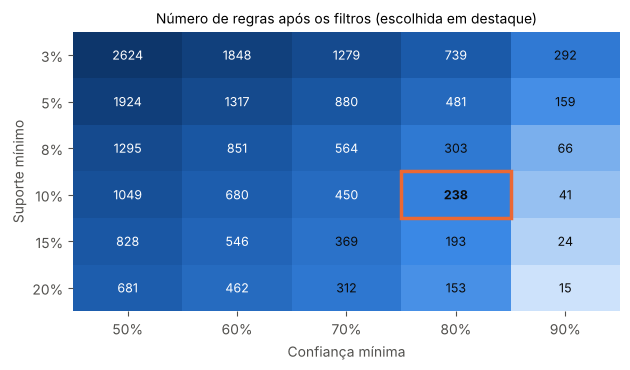

In [14]:
# Mapa de calor do número de regras após os filtros
from matplotlib.colors import LinearSegmentedColormap
azuis = LinearSegmentedColormap.from_list("azuis", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

tab = grade.pivot(index="suporte_min", columns="confianca_min", values="regras_filtradas")
fig, ax = plt.subplots(figsize=(6.4, 3.8))
im = ax.imshow(np.log10(tab.values), cmap=azuis, aspect="auto")
ax.set_xticks(range(len(tab.columns)), [f"{c:.0%}" for c in tab.columns])
ax.set_yticks(range(len(tab.index)), [f"{s:.0%}" for s in tab.index])
ax.set_xlabel("Confiança mínima"); ax.set_ylabel("Suporte mínimo")
limiar = np.log10(tab.values).mean()
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        ax.text(j, i, str(v), ha="center", va="center", fontsize=9,
                color="white" if np.log10(v) > limiar else "#0b0b0b",
                fontweight="bold" if (tab.index[i] == 0.10 and tab.columns[j] == 0.8) else "normal")
# destaca a configuração escolhida
i_e, j_e = list(tab.index).index(0.10), list(tab.columns).index(0.8)
ax.add_patch(plt.Rectangle((j_e - 0.5, i_e - 0.5), 1, 1, fill=False, ec=LARANJA, lw=2.5))
for s in ax.spines.values(): s.set_visible(False)
ax.set_title("Número de regras após os filtros (escolhida em destaque)", fontsize=10)
plt.tight_layout()
plt.savefig("figs/grade_regras.png", dpi=200, bbox_inches="tight")
plt.show()

**Escolha: suporte mínimo = 10% e confiança mínima = 80%** (antecedente com até 3 itens).

- **Suporte 10%** corresponde a pelo menos 89 passageiros por regra — grupos grandes o bastante para não refletirem casos isolados. Com 3–5% o número de regras filtradas passa de mil, a maioria descrevendo subgrupos pequenos e sobrepostos. Com 15–20% somem quase todas as regras de `Sobreviveu=Sim`, porque o grupo mais típico de sobreviventes (mulheres da 1ª classe) tem suporte de apenas 10,2%.
- **Confiança 80%** garante regras fortes. Para `Sobreviveu=Sim` (taxa base de 38,4%) isso implica lift ≥ 2,08; para `Sobreviveu=Não` (61,6%), lift ≥ 1,30. Com 90% sobram pouquíssimas regras de sobrevivência; com 50–70% entram regras fracas para `Sobreviveu=Não`, cuja confiança fica perto da taxa base.

### 3(a) e 3(c) Regras finais com suporte, confiança e lift

In [15]:
SUP_MIN, CONF_MIN = 0.10, 0.80

regras_todas, suportes_freq, n_freq_bruto, n_freq = gerar_regras(transacoes, SUP_MIN, CONF_MIN)
print(f"Itemsets frequentes: {n_freq_bruto} (sem tautologias: {n_freq})")
print(f"Regras com confiança >= {CONF_MIN:.0%}: {len(regras_todas)}")

regras_finais = filtrar_regras(regras_todas, suportes_freq).copy()
print(f"Regras após os filtros de qualidade: {len(regras_finais)}")

def fmt(itemset):
    return "{" + ", ".join(sorted(itemset, key=lambda i: (i.startswith("NÃO"), i))) + "}"

regras_finais["Antecedente"] = regras_finais["antecedents"].apply(fmt)
regras_finais["Consequente"] = regras_finais["consequents"].apply(fmt)
regras_finais["n_ausencia"] = regras_finais["antecedents"].apply(lambda s: sum(i.startswith("NÃO") for i in s))
regras_finais = regras_finais.sort_values(["lift", "confidence"], ascending=False).reset_index(drop=True)
regras_finais.index = regras_finais.index + 1

colunas = ["Antecedente", "Consequente", "support", "confidence", "lift"]
tabela_final = regras_finais[colunas + ["n_ausencia"]].rename(
    columns={"support": "Suporte", "confidence": "Confiança", "lift": "Lift"})
tabela_final.round(3).to_csv("regras_finais.csv", index_label="Regra")

# Todas as regras finais, com suporte, confiança e lift
with pd.option_context("display.max_rows", None):
    display(tabela_final[["Antecedente", "Consequente", "Suporte", "Confiança", "Lift"]].round(3))

Itemsets frequentes: 13140 (sem tautologias: 6024)
Regras com confiança >= 80%: 10182
Regras após os filtros de qualidade: 238


,Antecedente,Consequente,Suporte,Confiança,Lift
1,"{Classe=1ª, NÃO Família=Sozinho}",{Tarifa=Alta},0.118,0.981,3.737
2,"{Classe=1ª, Família=Pequena}",{Tarifa=Alta},0.111,0.980,3.732
3,"{Sobreviveu=Sim, Tarifa=Alta, NÃO Idade=0-17}",{Classe=1ª},0.117,0.897,3.698
4,"{Tarifa=Alta, NÃO Família=Grande, NÃO Idade=0-17}",{Classe=1ª},0.169,0.863,3.559
5,"{Sobreviveu=Sim, Tarifa=Alta}",{Classe=1ª},0.129,0.846,3.488
6,"{Tarifa=Alta, NÃO Família=Grande}",{Classe=1ª},0.183,0.840,3.466
7,"{Família=Pequena, Tarifa=Alta}",{Classe=1ª},0.111,0.825,3.403
8,"{Tarifa=Alta, NÃO Idade=0-17}",{Classe=1ª},0.176,0.809,3.338
9,"{Classe=1ª, Sobreviveu=Sim}",{Tarifa=Alta},0.129,0.846,3.220
10,"{Classe=1ª, NÃO Idade=41+}",{Tarifa=Alta},0.126,0.806,3.068


## 4. Análise dos resultados

### 4(a) Regras mais relevantes (ordenadas por lift)

In [16]:
tabela_final[["Antecedente", "Consequente", "Suporte", "Confiança", "Lift"]].head(20).round(3)

,Antecedente,Consequente,Suporte,Confiança,Lift
1,"{Classe=1ª, NÃO Família=Sozinho}",{Tarifa=Alta},0.118,0.981,3.737
2,"{Classe=1ª, Família=Pequena}",{Tarifa=Alta},0.111,0.980,3.732
3,"{Sobreviveu=Sim, Tarifa=Alta, NÃO Idade=0-17}",{Classe=1ª},0.117,0.897,3.698
4,"{Tarifa=Alta, NÃO Família=Grande, NÃO Idade=0-17}",{Classe=1ª},0.169,0.863,3.559
5,"{Sobreviveu=Sim, Tarifa=Alta}",{Classe=1ª},0.129,0.846,3.488
6,"{Tarifa=Alta, NÃO Família=Grande}",{Classe=1ª},0.183,0.840,3.466
7,"{Família=Pequena, Tarifa=Alta}",{Classe=1ª},0.111,0.825,3.403
8,"{Tarifa=Alta, NÃO Idade=0-17}",{Classe=1ª},0.176,0.809,3.338
9,"{Classe=1ª, Sobreviveu=Sim}",{Tarifa=Alta},0.129,0.846,3.220
10,"{Classe=1ª, NÃO Idade=41+}",{Tarifa=Alta},0.126,0.806,3.068


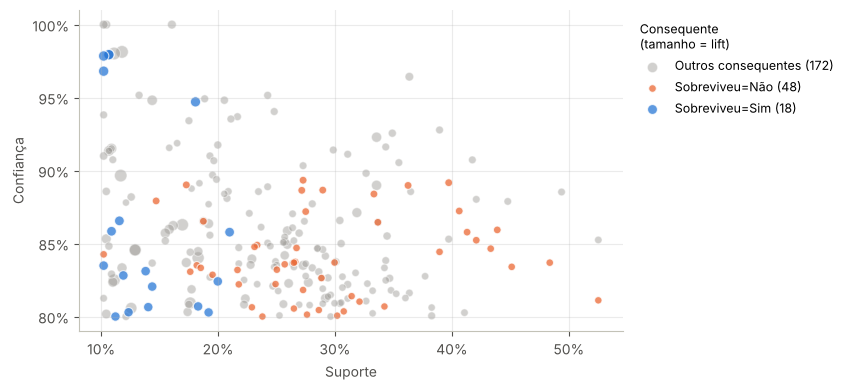

In [17]:
# Visão geral das regras finais: suporte x confiança, cor = tipo de consequente
grupo = np.where(regras_finais["Consequente"] == "{Sobreviveu=Sim}", "Sobreviveu=Sim",
         np.where(regras_finais["Consequente"] == "{Sobreviveu=Não}", "Sobreviveu=Não", "Outros consequentes"))
fig, ax = plt.subplots(figsize=(8.6, 4))
for nome, cor in [("Outros consequentes", CINZA), ("Sobreviveu=Não", LARANJA), ("Sobreviveu=Sim", AZUL)]:
    m = grupo == nome
    ax.scatter(regras_finais.loc[m, "support"], regras_finais.loc[m, "confidence"],
               s=regras_finais.loc[m, "lift"] * 22, color=cor, alpha=0.75 if nome != "Outros consequentes" else 0.45,
               edgecolor="white", linewidth=0.8, label=f"{nome} ({m.sum()})")
ax.set_xlabel("Suporte"); ax.set_ylabel("Confiança")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_locator(plt.matplotlib.ticker.MultipleLocator(0.05))
ax.grid(alpha=0.25)
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1.0),
          title="Consequente\n(tamanho = lift)", title_fontsize=9, alignment="left")
plt.tight_layout()
plt.savefig("figs/dispersao_regras.png", dpi=200, bbox_inches="tight")
plt.show()

### 4(b) Regras cujo consequente é a sobrevivência

In [18]:
cols = ["Antecedente", "Suporte", "Confiança", "Lift", "n_ausencia"]
regras_sim = tabela_final[tabela_final["Consequente"] == "{Sobreviveu=Sim}"][cols]
regras_nao = tabela_final[tabela_final["Consequente"] == "{Sobreviveu=Não}"][cols]
regras_sim.round(3).to_csv("regras_sobreviveu_sim.csv", index_label="Regra")
regras_nao.round(3).to_csv("regras_sobreviveu_nao.csv", index_label="Regra")

print(f"Regras -> Sobreviveu=Sim: {len(regras_sim)} | com itens de ausência: {(regras_sim.n_ausencia > 0).sum()}")
print(f"Regras -> Sobreviveu=Não: {len(regras_nao)} | com itens de ausência: {(regras_nao.n_ausencia > 0).sum()}")
regras_sim.round(3)

Regras -> Sobreviveu=Sim: 18 | com itens de ausência: 14
Regras -> Sobreviveu=Não: 48 | com itens de ausência: 36


,Antecedente,Suporte,Confiança,Lift,n_ausencia
11,"{Sexo=Feminino, Tarifa=Alta, NÃO Classe=3ª}",0.107,0.979,2.552,1
12,"{Sexo=Feminino, NÃO Classe=3ª, NÃO Tarifa=Média}",0.107,0.979,2.552,2
13,"{Sexo=Feminino, Tarifa=Alta, NÃO Família=Grande}",0.102,0.978,2.549,1
16,"{Classe=1ª, Sexo=Feminino}",0.102,0.968,2.522,0
18,"{Sexo=Feminino, NÃO Classe=3ª}",0.181,0.947,2.467,1
30,"{Idade=23-40, Sexo=Feminino, NÃO Tarifa=Baixa}",0.116,0.866,2.255,1
31,"{Sexo=Feminino, Tarifa=Alta}",0.109,0.858,2.236,0
32,"{Sexo=Feminino, NÃO Família=Grande, NÃO Tarifa=Baixa}",0.210,0.858,2.235,2
36,"{Sexo=Feminino, NÃO Embarque=Southampton}",0.102,0.835,2.175,1
38,"{Família=Pequena, Sexo=Feminino, NÃO Tarifa=Baixa}",0.138,0.831,2.165,1


In [19]:
with pd.option_context("display.max_rows", None):
    display(regras_nao.round(3))

,Antecedente,Suporte,Confiança,Lift,n_ausencia
98,"{Sexo=Masculino, Tarifa=Baixa}",0.273,0.893,1.450,0
100,"{Sexo=Masculino, NÃO Classe=1ª, NÃO Idade=0-17}",0.397,0.892,1.447,2
102,"{Sexo=Masculino, NÃO Família=Pequena, NÃO Idade=23-40}",0.173,0.890,1.445,2
104,"{Sexo=Masculino, NÃO Classe=1ª, NÃO Família=Pequena}",0.363,0.890,1.444,2
106,"{Classe=3ª, Sexo=Masculino, NÃO Família=Pequena}",0.290,0.887,1.439,1
107,"{Idade=23-40, Sexo=Masculino, NÃO Classe=1ª}",0.272,0.886,1.439,1
108,"{Família=Sozinho, Sexo=Masculino, NÃO Classe=1ª}",0.333,0.884,1.435,1
111,"{Família=Sozinho, Sexo=Masculino, NÃO Idade=23-40}",0.147,0.879,1.427,1
113,"{Sexo=Masculino, NÃO Idade=0-17, NÃO Tarifa=Alta}",0.406,0.872,1.416,2
115,"{Idade=23-40, Sexo=Masculino, NÃO Tarifa=Alta}",0.275,0.872,1.415,1


### Tabelas de apoio à interpretação

Taxas de sobrevivência por combinações de atributos, calculadas diretamente na base — servem para conferir e contextualizar as regras.

In [20]:
def taxa(mascara):
    g = dados[mascara]
    return pd.Series({"Passageiros": len(g), "Suporte": round(len(g) / len(dados), 3),
                      "Sobrevivência": round((g["Sobreviveu"] == "Sim").mean(), 3)})

print("Sobrevivência por sexo e classe")
print(dados.assign(s=(dados["Sobreviveu"] == "Sim")).pivot_table(index="Sexo", columns="Classe", values="s", aggfunc="mean").round(3))
print("\nSobrevivência por sexo e faixa etária")
print(dados.assign(s=(dados["Sobreviveu"] == "Sim")).pivot_table(index="Sexo", columns="Idade", values="s", aggfunc="mean").round(3))

grupos = {
    "Mulheres": dados.Sexo == "Feminino",
    "Mulheres na 1ª ou 2ª classe (NÃO Classe=3ª)": (dados.Sexo == "Feminino") & (dados.Classe != "3ª"),
    "Mulheres na 3ª classe": (dados.Sexo == "Feminino") & (dados.Classe == "3ª"),
    "Homens": dados.Sexo == "Masculino",
    "Homens adultos fora da 1ª classe": (dados.Sexo == "Masculino") & (dados.Classe != "1ª") & (dados.Idade != "0-17"),
    "Homens na 1ª classe": (dados.Sexo == "Masculino") & (dados.Classe == "1ª"),
    "Meninos (0-17)": (dados.Sexo == "Masculino") & (dados.Idade == "0-17"),
    "Menores (0-17) fora da 3ª classe": (dados.Idade == "0-17") & (dados.Classe != "3ª"),
}
apoio = pd.DataFrame({k: taxa(m) for k, m in grupos.items()}).T
apoio.to_csv("tabelas_apoio.csv")
apoio

Sobrevivência por sexo e classe
Classe        1ª     2ª     3ª
Sexo                          
Feminino   0.968  0.921  0.500
Masculino  0.369  0.157  0.135

Sobrevivência por sexo e faixa etária
Idade       0-17  18-22  23-40    41+
Sexo                                 
Feminino   0.691  0.649  0.803  0.771
Masculino  0.403  0.104  0.173  0.175


,Passageiros,Suporte,Sobrevivência
Mulheres,314.0,0.352,0.742
Mulheres na 1ª ou 2ª classe (NÃO Classe=3ª),170.0,0.191,0.947
Mulheres na 3ª classe,144.0,0.162,0.500
Homens,577.0,0.648,0.189
Homens adultos fora da 1ª classe,397.0,0.446,0.108
Homens na 1ª classe,122.0,0.137,0.369
Meninos (0-17),62.0,0.070,0.403
Menores (0-17) fora da 3ª classe,35.0,0.039,0.914


### 4(c) Interpretação

A interpretação detalhada de cada regra (com os números acima) está no relatório em PDF. Em resumo:

- **Sexo é o fator dominante.** Todas as regras com consequente `Sobreviveu=Sim` têm `Sexo=Feminino` no antecedente; a regra de 1 item `{Sexo=Masculino} → {Sobreviveu=Não}` já tem confiança de 81%.
- **Classe e tarifa modulam o efeito do sexo.** Mulheres que **não** estavam na 3ª classe sobreviveram em cerca de 95% dos casos, enquanto as da 3ª classe ficaram perto de 50%. Já os homens adultos fora da 1ª classe morreram em cerca de 89% dos casos.
- **Os itens de ausência agrupam categorias.** `NÃO Classe=3ª` junta 1ª e 2ª classes; `NÃO Idade=0-17` representa "adulto". Isso permite regras mais gerais, com maior suporte, que não seriam expressas por um único item de presença.
- **Regras de perfil** (sem sobrevivência no consequente) mostram a estrutura socioeconômica: 1ª classe ↔ tarifa alta, 3ª classe ↔ tarifa baixa e viagem sozinho. Também mostram um detalhe da base: a tarifa é por **bilhete**, então famílias na 1ª classe aparecem com tarifa alta.